## **Data Preprocessing**

In [103]:
import re
import numpy as np        
import pandas as pd 
from datetime import datetime
import seaborn as sns 
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector as selector

### Feature Cleaning

In [2]:
df = pd.DataFrame({
    "Date": ["2023-12-01", "12/01/2023", "01.12.2023", None, "2023/12/01", "1 Dec 2023", "2023.12.01", "Dec 01, 2023", "2023-01-12", "2023-13-01"],
    "Country": ["Deutschland", "Germany", "DE", "germany", "Österreich", "Austria", None, "deutschland", "USA", "Vereinigte Staaten"],
    "JobTitle": [" Data Scientist ", "Engineer", "  Manager", "data-scientist ", "Analyst", " Product Manager ", "", " ML Engineer", "CEO ", " "],
    "Category": ["1", 1, "1.0", None, 1.0, "3", "0", "4.0", "five", "2"],
    "Height": [170, 1.75, "180 cm", "1.8 m", "165cm", None, "2.0m", "190", "175 cm", "1,70"],
    "Price": ["$1200", "€900", None, "1,500", "£800", "$1,000", "900", "1.2k", "USD 700", "€1.000"],
    "Approved": ["yes", "no", "Y", "N", "True", "FALSE", "1", "0", "t", "f"],
})
df

,Date,Country,JobTitle,Category,Height,Price,Approved
0,2023-12-01,Deutschland,Data Scientist,1,170,$1200,yes
1,12/01/2023,Germany,Engineer,1,1.75,€900,no
2,01.12.2023,DE,Manager,1.0,180 cm,None,Y
3,None,germany,data-scientist,None,1.8 m,"1,500",N
4,2023/12/01,Österreich,Analyst,1.0,165cm,£800,True
5,1 Dec 2023,Austria,Product Manager,3,None,"$1,000",FALSE
6,2023.12.01,None,,0,2.0m,900,1
7,"Dec 01, 2023",deutschland,ML Engineer,4.0,190,1.2k,0
8,2023-01-12,USA,CEO,five,175 cm,USD 700,t
9,2023-13-01,Vereinigte Staaten,,2,"1,70",€1.000,f


In [116]:
df.dtypes

Date        object
Country     object
JobTitle    object
Category    object
Height      object
Price       object
Approved    object
dtype: object

In [70]:
df.isna().sum()

Date        1
Country     1
JobTitle    0
Category    1
Height      1
Price       1
Approved    0
dtype: int64

In [101]:
df_clean = df.copy()

In [104]:
def parse_mixed_date(value):
    if pd.isna(value) or str(value).strip() == "":
        return None

    value = str(value).strip()

    formats = [
        "%Y-%m-%d",   # 2023-12-01
        "%m/%d/%Y",   # 12/01/2023 -> 2023-12-01
        "%d.%m.%Y",   # 01.12.2023
        "%Y/%m/%d",   # 2023/12/01
        "%d %b %Y",   # 1 Dec 2023
        "%Y.%m.%d",   # 2023.12.01
        "%b %d, %Y",  # Dec 01, 2023
    ]

    for fmt in formats:
        try:
            dt = datetime.strptime(value, fmt)
            return dt.strftime("%Y-%m-%d")
        except ValueError:
            continue

    return None

df_clean["Date"] = df_clean["Date"].apply(parse_mixed_date)
df_clean["Date"]

0    2023-12-01
1    2023-12-01
2    2023-12-01
3          None
4    2023-12-01
5    2023-12-01
6    2023-12-01
7    2023-12-01
8    2023-01-12
9          None
Name: Date, dtype: object

In [24]:
def clean_country(x):
    if pd.isna(x): return pd.NA
    s = str(x).strip().lower()
    mapping = {
        "de": "Germany",
        "deutschland": "Germany",
        "germany": "Germany",
        "österreich": "Austria",
        "austria": "Austria",
        "usa": "United States",
        "vereinigte staaten": "United States",
        "us": "United States",
        "u.s.a.": "United States",
    }
    return mapping.get(s, s.title())

df_clean["Country"] = df_clean["Country"].apply(clean_country)
df_clean["Country"]

0          Germany
1          Germany
2          Germany
3          Germany
4          Austria
5          Austria
6             <NA>
7          Germany
8    United States
9    United States
Name: Country, dtype: object

In [25]:
def clean_job_title(x):
    if pd.isna(x): return pd.NA
    s = str(x).strip().lower()
    if s in {"", " "}: return pd.NA
    s = s.replace("-", " ")
    s = re.sub(r"\s+", " ", s)

    synonyms = {
        "ml engineer": "machine learning engineer",
        "data scientist": "data scientist",
        "product manager": "product manager",
        "manager": "manager",
        "engineer": "engineer",
        "analyst": "analyst",
        "intern": "intern",
        "ceo": "ceo",
    }
    return synonyms.get(s, s)

df_clean["JobTitle"] = df_clean["JobTitle"].apply(clean_job_title)
df_clean["JobTitle"]

0               data scientist
1                     engineer
2                      manager
3               data scientist
4                      analyst
5              product manager
6                         <NA>
7    machine learning engineer
8                          ceo
9                         <NA>
Name: JobTitle, dtype: object

In [28]:
df_clean["Category"] = pd.to_numeric(df_clean["Category"], errors="coerce")
df_clean["Category"]

0    1.0
1    1.0
2    1.0
3    NaN
4    1.0
5    3.0
6    0.0
7    4.0
8    NaN
9    2.0
Name: Category, dtype: float64

In [32]:
def normalize_height_to_cm(x):
    if pd.isna(x): return np.nan
    raw = str(x).strip().lower()
    if raw == "": return np.nan

    has_m  = "m" in raw
    has_cm = "cm" in raw

    s = re.sub(r"[^\d.,-]", "", raw)  

    # Mixed separators
    if "," in s and "." in s:
        if s.rfind(",") > s.rfind("."):
            s = s.replace(".", "").replace(",", ".")
        else:
            s = s.replace(",", "")
    elif "," in s:
        parts = s.split(",")
        if len(parts) > 1 and len(parts[-1]) == 3 and all(p.isdigit() for p in parts):
            s = s.replace(",", "")
        else:
            s = s.replace(",", ".")
    else:
        if s.count(".") > 1:
            s = s.replace(".", "")

    try:
        val = float(s)
    except ValueError:
        return np.nan

    if has_cm or (not has_m and val >= 3):
        return float(val)               
    else:
        return float(val * 100.0)
        
df_clean["Height"] = df_clean["Height"].apply(normalize_height_to_cm)
df_clean["Height"]

0    170.0
1    175.0
2    180.0
3    180.0
4    165.0
5      NaN
6    200.0
7    190.0
8    175.0
9    170.0
Name: Height, dtype: float64

In [37]:
def parse_number_mixed_locale(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s == "":
        return np.nan

    if s.lower().endswith("k"):
        try:
            return float(s[:-1].strip().replace(",", ".")) * 1000
        except ValueError:
            return np.nan

    s = re.sub(r"[^\d.,-]", "", s)
    if s == "":
        return np.nan

    def looks_like_thousands(groups):
        return (
            len(groups[0]) in (1, 2, 3)
            and all(len(g) == 3 for g in groups[1:])
            and all(g.isdigit() for g in groups)
        )

    if "," in s and "." in s:
        if s.rfind(",") > s.rfind("."):
            s = s.replace(".", "").replace(",", ".")
        else:
            s = s.replace(",", "")
    elif "," in s:
        parts = s.split(",")
        if looks_like_thousands(parts):
            s = "".join(parts)
        else:
            s = s.replace(",", ".")
    elif "." in s:
        parts = s.split(".")
        if looks_like_thousands(parts):
            s = "".join(parts)

    try:
        return float(s)
    except ValueError:
        return np.nan


df_clean["Price"] = df_clean["Price"].apply(parse_number_mixed_locale)
df_clean["Price"]

0    1200.0
1     900.0
2       NaN
3    1500.0
4     800.0
5    1000.0
6     900.0
7    1200.0
8     700.0
9    1000.0
Name: Price, dtype: float64

In [39]:
def normalize_bool(x):
    if pd.isna(x): 
        return pd.NA
    s = str(x).strip().lower()
    truthy = {"yes","y","true","t","1"}
    falsy  = {"no","n","false","f","0"}
    if s in truthy: return True
    if s in falsy:  return False
    return pd.NA
    
df_clean["Approved"] = df_clean["Approved"].apply(normalize_bool).astype("boolean")
df_clean["Approved"]

0     True
1    False
2     True
3    False
4     True
5    False
6     True
7    False
8     True
9    False
Name: Approved, dtype: boolean

In [133]:
df_clean.dtypes

Date         object
Country      object
JobTitle     object
Category    float64
Height      float64
Price       float64
Approved    boolean
dtype: object

### California Housing Dataset

In [113]:
# მონაცემების ჩატვირთვა
df_housing = pd.read_csv("../../datasets/house_prices/california_housing.csv")
df_housing.head()

,MedInc,HouseAge,TotalRooms,TotalBedrms,Population,Households,Latitude,Longitude,MedHouseVal,OceanProximity
0,8.3252,41.0,880.0,129.0,322.0,126.0,37.88,-122.23,452600.0,NEAR BAY
1,8.3014,21.0,7099.0,1106.0,2401.0,1138.0,37.86,-122.22,358500.0,NEAR BAY
2,7.2574,52.0,1467.0,190.0,496.0,177.0,37.85,-122.24,352100.0,NEAR BAY
3,5.6431,52.0,1274.0,235.0,558.0,219.0,37.85,-122.25,341300.0,NEAR BAY
4,3.8462,52.0,1627.0,280.0,565.0,259.0,37.85,-122.25,342200.0,NEAR BAY


In [114]:
df_housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   MedInc          20640 non-null  float64
 1   HouseAge        20640 non-null  float64
 2   TotalRooms      20640 non-null  float64
 3   TotalBedrms     20433 non-null  float64
 4   Population      20640 non-null  float64
 5   Households      20640 non-null  float64
 6   Latitude        20640 non-null  float64
 7   Longitude       20640 non-null  float64
 8   MedHouseVal     20640 non-null  float64
 9   OceanProximity  20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [115]:
df_housing.isnull().sum()

MedInc              0
HouseAge            0
TotalRooms          0
TotalBedrms       207
Population          0
Households          0
Latitude            0
Longitude           0
MedHouseVal         0
OceanProximity      0
dtype: int64

In [116]:
df_housing.drop("TotalBedrms", axis=1)

,MedInc,HouseAge,TotalRooms,Population,Households,Latitude,Longitude,MedHouseVal,OceanProximity
0,8.3252,41.0,880.0,322.0,126.0,37.88,-122.23,452600.0,NEAR BAY
1,8.3014,21.0,7099.0,2401.0,1138.0,37.86,-122.22,358500.0,NEAR BAY
2,7.2574,52.0,1467.0,496.0,177.0,37.85,-122.24,352100.0,NEAR BAY
3,5.6431,52.0,1274.0,558.0,219.0,37.85,-122.25,341300.0,NEAR BAY
4,3.8462,52.0,1627.0,565.0,259.0,37.85,-122.25,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,1665.0,845.0,330.0,39.48,-121.09,78100.0,INLAND
20636,2.5568,18.0,697.0,356.0,114.0,39.49,-121.21,77100.0,INLAND
20637,1.7000,17.0,2254.0,1007.0,433.0,39.43,-121.22,92300.0,INLAND
20638,1.8672,18.0,1860.0,741.0,349.0,39.43,-121.32,84700.0,INLAND


In [117]:
# Handle None values 
df_housing.dropna(subset=["TotalBedrms"]) # option 1 

df_housing.drop("TotalBedrms", axis=1) # option 2 

median = df_housing["TotalBedrms"].median() # option 3 
df_housing["TotalBedrms"] = df_housing["TotalBedrms"].fillna(median)

In [118]:
# With SimpleImputer
imputer = SimpleImputer(strategy="median")
df_housing["TotalBedrms"] = imputer.fit_transform(df_housing[["TotalBedrms"]])

In [119]:
df_housing.describe()[["MedInc", "HouseAge", "TotalRooms", "TotalBedrms", "Population", "Households", "MedHouseVal"]]

,MedInc,HouseAge,TotalRooms,TotalBedrms,Population,Households,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,2635.763081,536.838857,1425.476744,499.539680,206855.816909
std,1.899822,12.585558,2181.615252,419.391878,1132.462122,382.329753,115395.615874
min,0.499900,1.000000,2.000000,1.000000,3.000000,1.000000,14999.000000
25%,2.563400,18.000000,1447.750000,297.000000,787.000000,280.000000,119600.000000
50%,3.534800,29.000000,2127.000000,435.000000,1166.000000,409.000000,179700.000000
75%,4.743250,37.000000,3148.000000,643.250000,1725.000000,605.000000,264725.000000
max,15.000100,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,500001.000000


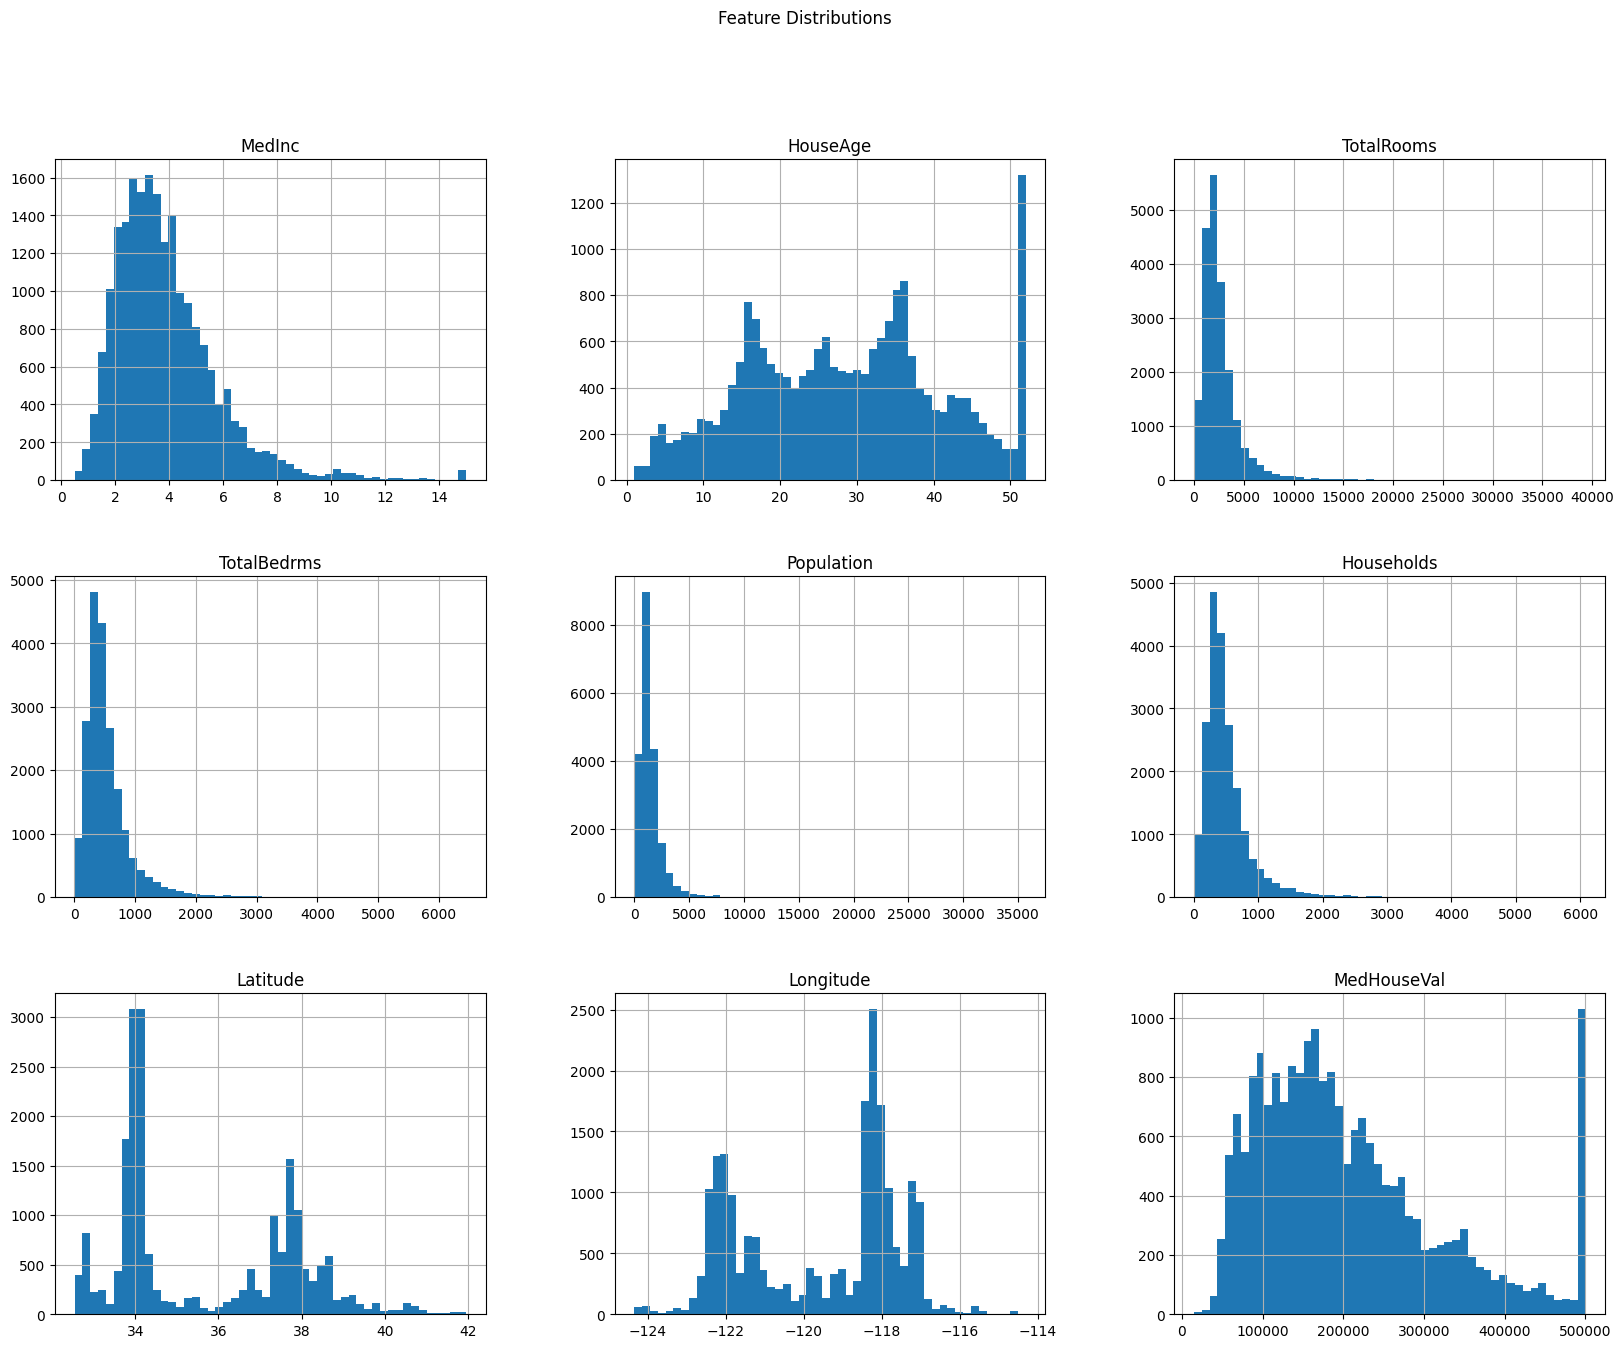

In [120]:
df_housing.hist(figsize=(20, 15), bins=50)
plt.suptitle("Feature Distributions")
plt.show()

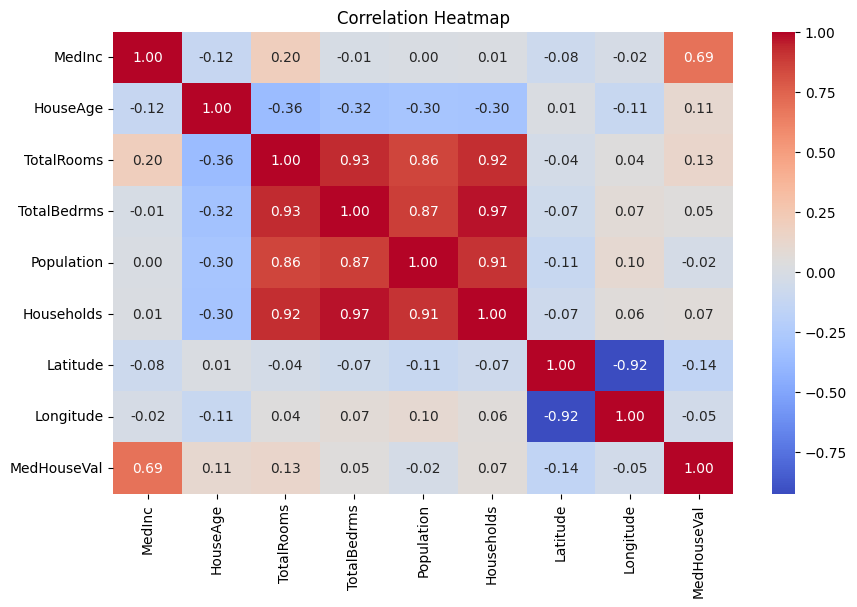

In [121]:
plt.figure(figsize=(10,6))
sns.heatmap(df_housing.drop("OceanProximity", axis=1).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

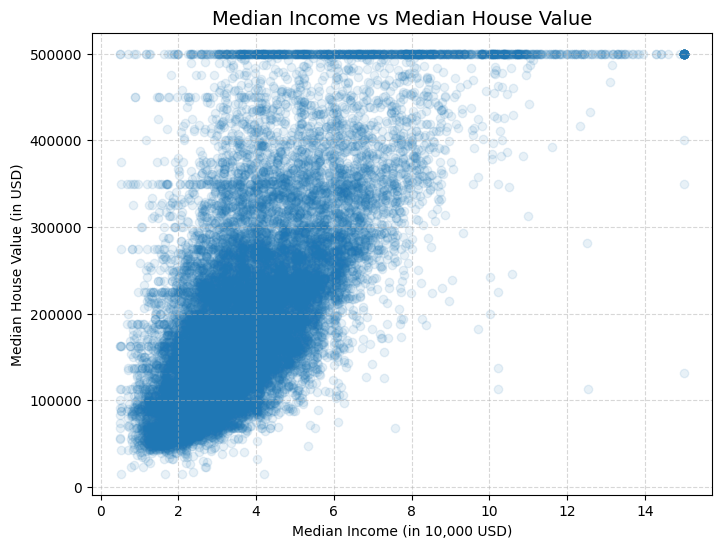

In [122]:
plt.figure(figsize=(8, 6))
plt.scatter(df_housing["MedInc"], df_housing["MedHouseVal"], alpha=0.1)
plt.title("Median Income vs Median House Value", fontsize=14)
plt.xlabel("Median Income (in 10,000 USD)")
plt.ylabel("Median House Value (in USD)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

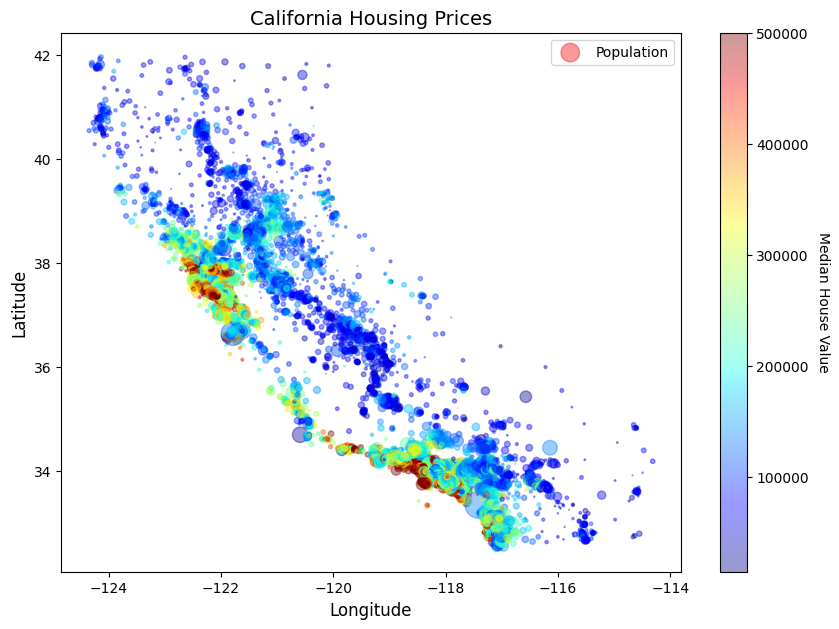

In [123]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    df_housing["Longitude"],
    df_housing["Latitude"],
    alpha=0.4,
    s=df_housing["Population"] / 100,   # bubble size
    c=df_housing["MedHouseVal"],        # color = house value
    cmap="jet",
    label="Population"
)

plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.title("California Housing Prices", fontsize=14)
cbar = plt.colorbar(scatter)
cbar.set_label("Median House Value", rotation=270, labelpad=15)
plt.legend()
plt.show()

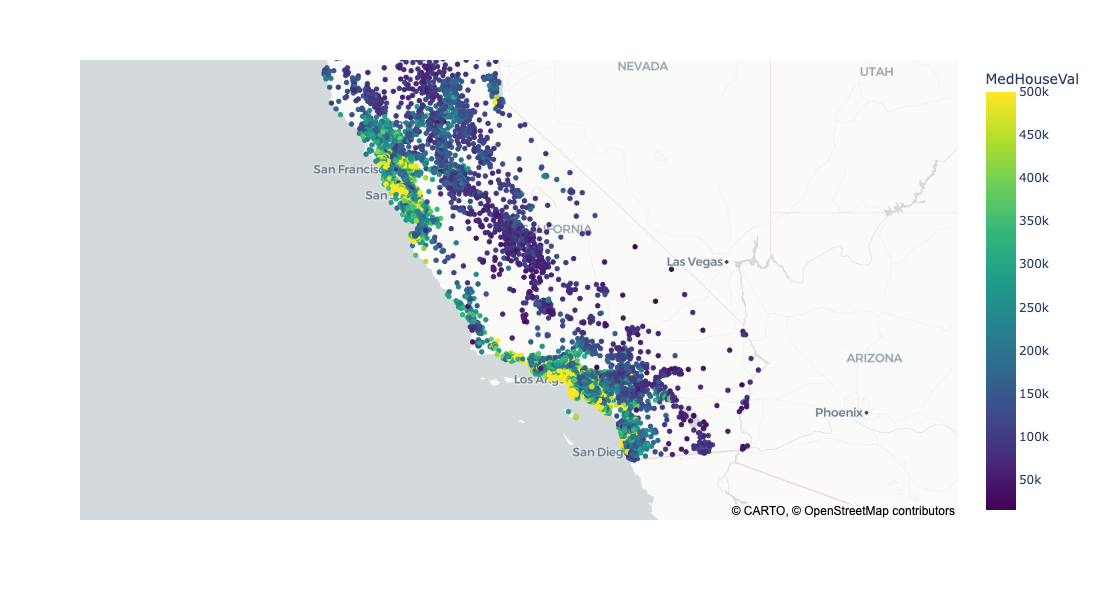

In [124]:
fig = px.scatter_map(
    df_housing,
    lat="Latitude",
    lon="Longitude",
    color="MedHouseVal",
    hover_data=["MedInc", "HouseAge"],
    color_continuous_scale="Viridis",
    zoom=5,
    height=600,
    size_max=5,
    map_style="carto-positron" # open-street-map
)
fig.show()

In [125]:
# შევქმნათ შემოსავლის კატეგორიის სვეტი
df_housing["IncomeCat"] = pd.cut(df_housing["MedInc"], bins=[0., 1.5, 3.0, 4.5, 6., np.inf], labels=[1, 2, 3, 4, 5])

In [126]:
# Derive ratio features
df_housing["RoomsPerHousehold"] = df_housing["TotalRooms"] / df_housing["Households"]
df_housing["BedrmsPerRoom"] = df_housing["TotalBedrms"] / df_housing["TotalRooms"]
df_housing["PopPerHousehold"] = df_housing["Population"] / df_housing["Households"]

In [127]:
corr_matrix = df_housing.drop("OceanProximity", axis=1).corr()
corr_matrix["MedHouseVal"].sort_values(ascending=False)

MedHouseVal          1.000000
MedInc               0.688075
IncomeCat            0.643892
RoomsPerHousehold    0.151948
TotalRooms           0.134153
HouseAge             0.105623
Households           0.065843
TotalBedrms          0.049457
PopPerHousehold     -0.023737
Population          -0.024650
Longitude           -0.045967
Latitude            -0.144160
BedrmsPerRoom       -0.233303
Name: MedHouseVal, dtype: float64

In [128]:
df_housing["OceanProximity"].value_counts()

OceanProximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [129]:
ordinal_encoder = OrdinalEncoder()
ordinal_encoder.fit_transform(df_housing[["OceanProximity"]])

array([[3.],
       [3.],
       [3.],
       ...,
       [1.],
       [1.],
       [1.]], shape=(20640, 1))

In [130]:
ordinal_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

ზოგიერთი ალგორითმი მიიჩნევს ასეთი კოდირების დროს რომ ახლოს მყოფი კატეგორიები უფრო მსგავსია ვიდრე ერთმანეთისგან დაშორებული კატეგორიები.

{'<1H OCEAN': 0,
 'INLAND': 1,
 'ISLAND': 2,
 'NEAR BAY': 3, 
 'NEAR OCEAN': 4
 }

 ანუ ამ შემთხვევისთვის ჩათვლის რომ კატეგორიები 0('<1H OCEAN') და 1 ('INLAND') მსგავსია, როცა კატეგორიები 0('<1H OCEAN') და 4 ('NEAR OCEAN') რეალურად უფრო ჰგვანან ერთმანეთს.

In [131]:
cat_encoder = OneHotEncoder(sparse_output=False, drop=None) 
housing_cat_encoded = cat_encoder.fit_transform(df_housing[["OceanProximity"]])
housing_cat_df = pd.DataFrame(
    housing_cat_encoded,
    columns=cat_encoder.get_feature_names_out(["OceanProximity"]),
    index=df_housing.index
)
housing_cat_df.head()

,OceanProximity_<1H OCEAN,OceanProximity_INLAND,OceanProximity_ISLAND,OceanProximity_NEAR BAY,OceanProximity_NEAR OCEAN
0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,1.0,0.0


### Pipeline

In [138]:
df_housing = pd.read_csv("../../datasets/house_prices/california_housing.csv")

In [139]:
def add_features(df_input):
    df = df_input.copy()
    df["RoomsPerHousehold"] = df["TotalRooms"] / df["Households"]
    df["BedrmsPerRoom"] = df["TotalBedrms"] / df["TotalRooms"]
    df["PopPerHousehold"] = df["Population"] / df["Households"]
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    return df

def add_features_names(transformer, input_features):
    return list(input_features) + [
        "RoomsPerHousehold",
        "BedrmsPerRoom",
        "PopPerHousehold",
    ]


feat_eng = FunctionTransformer(
    add_features,
    validate=False,
    feature_names_out=add_features_names
)

numeric_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocess = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, selector(dtype_include=np.number)),
    ("cat", categorical_pipeline, ["OceanProximity"]),
], remainder="drop")

pipe = Pipeline(steps=[
    ("feat_eng", feat_eng),
    ("preprocess", preprocess),
])

In [140]:
pipe = Pipeline(steps=[
    ("feat_eng", feat_eng),
    ("preprocess", preprocess),])
pipe

,steps,"[('feat_eng', ...), ('preprocess', ...)]"
,transform_input,None
,memory,None
,verbose,False
,func,<function add...t 0x14607c360>
,inverse_func,None
,validate,False
,accept_sparse,False
,check_inverse,True
,feature_names_out,<function add...t 0x14607d760>
,kw_args,None


In [142]:
# ხელით გადავცეთ სვეტების სახელები
cols = df_housing.drop(columns=["OceanProximity"]).columns.tolist()
cols = cols + [
    "RoomsPerHousehold",
    "BedrmsPerRoom",
    "PopPerHousehold",
    "OceanProximity_<1H OCEAN",
    "OceanProximity_INLAND",
    "OceanProximity_ISLAND",
    "OceanProximity_NEAR BAY",
    "OceanProximity_NEAR OCEAN",
]

df_housing_prepared = pd.DataFrame(pipe.fit_transform(df_housing), columns=cols)
df_housing_prepared.head()

,MedInc,HouseAge,TotalRooms,TotalBedrms,Population,Households,Latitude,Longitude,MedHouseVal,RoomsPerHousehold,BedrmsPerRoom,PopPerHousehold,OceanProximity_<1H OCEAN,OceanProximity_INLAND,OceanProximity_ISLAND,OceanProximity_NEAR BAY,OceanProximity_NEAR OCEAN
0,2.344766,0.982143,-0.804819,-0.972476,-0.974429,-0.977033,1.052548,-1.327835,2.129631,0.628559,-1.149930,-0.049597,0.0,0.0,0.0,1.0,0.0
1,2.332238,-0.607019,2.045890,1.357143,0.861439,1.669961,1.043185,-1.322844,1.314156,0.327041,-0.990381,-0.092512,0.0,0.0,0.0,1.0,0.0
2,1.782699,1.856182,-0.535746,-0.827024,-0.820777,-0.843637,1.038503,-1.332827,1.258693,1.155620,-1.445865,-0.025843,0.0,0.0,0.0,1.0,0.0
3,0.932968,1.856182,-0.624215,-0.719723,-0.766028,-0.733781,1.038503,-1.337818,1.165100,0.156966,-0.493627,-0.050329,0.0,0.0,0.0,1.0,0.0
4,-0.012881,1.856182,-0.462404,-0.612423,-0.759847,-0.629157,1.038503,-1.337818,1.172900,0.344711,-0.707889,-0.085616,0.0,0.0,0.0,1.0,0.0


In [143]:
# ან თვითონ შექმნას სვეტის სახელები pipe.set_output(transform="pandas")
pipe.set_output(transform="pandas")

df_housing_prepared = pipe.fit_transform(df_housing)
df_housing_prepared.head()

,num__MedInc,num__HouseAge,num__TotalRooms,num__TotalBedrms,num__Population,num__Households,num__Latitude,num__Longitude,num__MedHouseVal,num__RoomsPerHousehold,num__BedrmsPerRoom,num__PopPerHousehold,cat__OceanProximity_<1H OCEAN,cat__OceanProximity_INLAND,cat__OceanProximity_ISLAND,cat__OceanProximity_NEAR BAY,cat__OceanProximity_NEAR OCEAN
0,2.344766,0.982143,-0.804819,-0.972476,-0.974429,-0.977033,1.052548,-1.327835,2.129631,0.628559,-1.149930,-0.049597,0.0,0.0,0.0,1.0,0.0
1,2.332238,-0.607019,2.045890,1.357143,0.861439,1.669961,1.043185,-1.322844,1.314156,0.327041,-0.990381,-0.092512,0.0,0.0,0.0,1.0,0.0
2,1.782699,1.856182,-0.535746,-0.827024,-0.820777,-0.843637,1.038503,-1.332827,1.258693,1.155620,-1.445865,-0.025843,0.0,0.0,0.0,1.0,0.0
3,0.932968,1.856182,-0.624215,-0.719723,-0.766028,-0.733781,1.038503,-1.337818,1.165100,0.156966,-0.493627,-0.050329,0.0,0.0,0.0,1.0,0.0
4,-0.012881,1.856182,-0.462404,-0.612423,-0.759847,-0.629157,1.038503,-1.337818,1.172900,0.344711,-0.707889,-0.085616,0.0,0.0,0.0,1.0,0.0
